In [1]:
import ast
import hashlib
import json
import random
import re
import time
import warnings
from collections import defaultdict
from functools import partial
from itertools import product

warnings.filterwarnings('ignore', message='IProgress not found.*', module='tqdm.auto')

import matplotlib.pyplot as plt
import mlx.core as mx
import pandas as pd
from huggingface_hub import snapshot_download
from IPython.display import display
from mlx_lm import load, stream_generate
from mlx_lm.sample_utils import make_sampler
from pydantic import BaseModel, ConfigDict, ValidationError, field_validator


## 1. Данные и выборка

In [2]:
def read_json(path):
    with open(path, encoding='utf-8') as handle:
        return json.load(handle)

def write_json(path, value):
    with open(path, 'w', encoding='utf-8') as handle:
        json.dump(value, handle, ensure_ascii=False, indent=2)

FIELDS = ('drug', 'indication', 'positive_effect', 'adverse_reaction')
ALL_FIELDS = (*FIELDS, 'evidence')
ENTITY_FIELDS = {'Drugname': 'drug', 'Drugform': 'drug', 'DI': 'indication', 'ADR': 'adverse_reaction'}


In [3]:
grouped = defaultdict(list)
with open('rudrec_annotated.json', encoding='utf-8') as handle:
    for line in handle:
        row = ast.literal_eval(line.replace('NaN', 'None'))
        grouped[row['file_name']].append(row)

def entities_from(rows):
    return [entity for row in rows for entity in row['entities']]

def eligible_review(rows):
    types = {entity['entity_type'] for entity in entities_from(rows)}
    return bool(types & {'Drugname', 'Drugform'} and types & {'DI', 'ADR', 'Finding'})


In [4]:
eligible = sorted(name for name, rows in grouped.items() if eligible_review(rows))
selected_ids = random.Random(42).sample(eligible, 50)
positive_labels = read_json('positive_effect_labels.json')

def unique(values):
    return list(dict.fromkeys(value.strip() for value in values if value.strip()))

def collect_gold(rows):
    gold = {field: [] for field in ALL_FIELDS}
    for entity in entities_from(rows):
        field = ENTITY_FIELDS.get(entity['entity_type'])
        if field is None:
            continue
        gold[field].append(entity['entity_text'])
        gold['evidence'].append(entity['entity_text'])
    return gold


In [5]:
def build_review(number, source_id):
    rows = grouped[source_id]
    review_id = f'rudrec_{number:03d}'
    text = ' '.join(row['text'].strip() for row in rows if row['text'].strip())
    gold = collect_gold(rows)
    effects = positive_labels.get(review_id, [])
    if any(effect not in text for effect in effects):
        raise ValueError(f'Positive annotation absent from {review_id}')
    gold['positive_effect'] = effects
    gold['evidence'].extend(effects)
    gold = {field: unique(values) for field, values in gold.items()}
    return {'id': review_id, 'source_id': source_id, 'text': text, 'gold': gold}

selected_reviews = [build_review(i, name) for i, name in enumerate(selected_ids, 1)]
write_json('reviews_50.json', selected_reviews)
reviews = read_json('reviews_50.json')


In [6]:
review_by_id = {row['id']: row for row in reviews}
prompts = read_json('prompts.json')
generation_config = read_json('generation_config.json')
semantic_cases = read_json('semantic_cases.json')


## 2. Схема, проверка и повторный запрос

In [7]:
class ExtractionResult(BaseModel):
    model_config = ConfigDict(extra='forbid')
    drug: list[str]
    indication: list[str]
    positive_effect: list[str]
    adverse_reaction: list[str]
    evidence: list[str]

    @field_validator(*ALL_FIELDS)
    @classmethod
    def validate_items(cls, values):
        if any(not item.strip() for item in values):
            raise ValueError('List items must be non-empty strings')
        if len(values) != len(set(values)):
            raise ValueError('Duplicate list items are not allowed')
        return values


In [8]:
def validate_response(raw_response, text, check_evidence=True):
    result = ExtractionResult.model_validate_json(raw_response)
    missing = [fragment for fragment in result.evidence if fragment not in text]
    if check_evidence and missing:
        raise ValueError(f'Evidence is absent from source text: {missing}')
    return result

def validation_error_message(error):
    if not isinstance(error, ValidationError):
        return str(error)
    details = error.errors(include_url=False)
    return '; '.join(f"{'.'.join(map(str, item['loc'])) or 'response'}: {item['msg']}" for item in details)

def assess_response(raw_response, text, check_evidence=True):
    try:
        result = validate_response(raw_response, text, check_evidence)
        return {'valid': True, 'result': result.model_dump(), 'error': None}
    except (ValidationError, ValueError) as error:
        return {'valid': False, 'result': None, 'error': validation_error_message(error)}


In [9]:
def run_one(text, template, generate, version, config):
    if not text.strip():
        return {'valid': True, 'result': {field: [] for field in ALL_FIELDS}, 'attempts': []}
    original = template.replace('{text}', text)
    prompt = original
    attempts = []
    limit = 2 if version == 'version_2' else 1
    for number in range(1, limit + 1):
        raw, metadata = generate(prompt)
        check = assess_response(raw, text, version == 'version_2')
        attempt = {'number': number, 'raw_response': raw, **metadata}
        attempt.update(valid=check['valid'], error=check['error'])
        attempts.append(attempt)
        if check['valid']:
            break
        prompt = config['retry_template'].format(prompt=original, error=check['error'])
    return {'valid': check['valid'], 'result': check['result'], 'attempts': attempts}


## 3. Модель и получение ответов

In [10]:
RUN_NEW_MODEL_INFERENCE = False
RUN_SEMANTIC_CHECKS = False

def load_local_model(config):
    model_path = snapshot_download(repo_id=config['model_id'], revision=config['revision'])
    return load(model_path)

def generate_text(prompt, model, tokenizer, config):
    messages = [{'role': 'system', 'content': config['system_prompt']},
                {'role': 'user', 'content': prompt}]
    tokens = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True)
    mx.synchronize()
    started = time.perf_counter()
    chunks = list(stream_generate(model, tokenizer, prompt=tokens, max_tokens=config['max_tokens'],
                                  sampler=make_sampler(temp=config['temperature'])))
    mx.synchronize()
    metadata = {'seconds': time.perf_counter() - started, 'input_tokens': len(tokens),
                'output_tokens': chunks[-1].generation_tokens, 'finish_reason': chunks[-1].finish_reason}
    return ''.join(chunk.text for chunk in chunks), metadata


In [11]:
def run_review(review, version, generate):
    run = run_one(review['text'], prompts[version], generate, version, generation_config)
    return {'id': review['id'], 'source_id': review['source_id'], 'version': version,
            'text_sha256': hashlib.sha256(review['text'].encode()).hexdigest(), **run}

def save_predictions(predictions):
    table = pd.DataFrame(predictions)
    for field in ('result', 'attempts'):
        table[field] = table[field].map(lambda value: json.dumps(value, ensure_ascii=False))
    table.to_csv('predictions.csv', index=False, encoding='utf-8-sig')

def run_experiment(reviews, generate):
    predictions = []
    for version, review in product(('version_1', 'version_2'), reviews):
        predictions.append(run_review(review, version, generate))
        save_predictions(predictions)
    return predictions


In [12]:
if RUN_NEW_MODEL_INFERENCE or RUN_SEMANTIC_CHECKS:
    model, tokenizer = load_local_model(generation_config)
    generate = partial(generate_text, model=model, tokenizer=tokenizer, config=generation_config)

if RUN_NEW_MODEL_INFERENCE:
    predictions = run_experiment(reviews, generate)

prediction_table = pd.read_csv('predictions.csv', encoding='utf-8-sig', keep_default_na=False)
for field in ('result', 'attempts'):
    prediction_table[field] = prediction_table[field].map(
        json.loads)
predictions = prediction_table.to_dict('records')


## 4. Смысловые проверки модели

In [13]:
def semantic_passed(result, field, expected):
    if result is None:
        return False
    actual = result[field]
    if not expected:
        return actual == []
    return all(any(value in item for item in actual) for value in expected)

def run_semantic_case(case, generate, prompts, config):
    run = run_one(case['text'], prompts['version_2'], generate, 'version_2', config)
    passed = semantic_passed(run['result'], case['field'], case['expected'])
    return {**case, 'result': run['result'], 'passed': passed, 'attempts': run['attempts']}


In [14]:
if RUN_SEMANTIC_CHECKS:
    semantic_checks = [run_semantic_case(case, generate, prompts, generation_config) for case in semantic_cases]
    write_json('semantic_checks.json', semantic_checks)

semantic_checks = read_json('semantic_checks.json')
semantic_table = pd.DataFrame([{'case': row['case'], 'passed': semantic_passed(
    row['result'], row['field'], row['expected']), 'attempts': len(row['attempts'])} for row in semantic_checks])
display(semantic_table)


,case,passed,attempts
0,empty,True,0
1,no_drug,True,1
2,multiple,True,1
3,negation,True,1
4,hypothesis,True,2
5,other_person,True,1
6,quotation,True,1
7,typo,True,1


## 5. Сравнение результатов

In [15]:
def normalize(value):
    return re.sub(r'\s+', ' ', value.casefold().replace('ё', 'е')).strip(' .,:;!?()[]{}"\'«»')

def overlaps(left, right):
    a, b = normalize(left), normalize(right)
    return bool(a and b and (a in b or b in a))

def match_counts(predicted, gold):
    available = set(range(len(gold)))
    tp = 0
    for item in predicted:
        match = next((i for i in available if overlaps(item, gold[i])), None)
        if match is None:
            continue
        available.remove(match)
        tp += 1
    return tp, len(predicted) - tp, len(gold) - tp


In [16]:
def parse_model_json(raw):
    try:
        return json.loads(raw), True
    except json.JSONDecodeError:
        return None, False

def unsupported_count(result, fields, text):
    values = [value for field in fields if isinstance(result.get(field), list)
              for value in result[field]]
    return sum(isinstance(value, str) and value not in text for value in values)

def extraction_counts(result, gold):
    counts = [match_counts(result[field], gold[field]) for field in FIELDS]
    return [sum(values) for values in zip(*counts)]


In [17]:
def measure_prediction(row):
    review = review_by_id[row['id']]
    first = row['attempts'][0]['raw_response']
    raw, json_valid = parse_model_json(first)
    raw = raw if isinstance(raw, dict) else {}
    result = row['result'] or {field: [] for field in ALL_FIELDS}
    tp, fp, fn = extraction_counts(result, review['gold'])
    return {'version': row['version'], 'tp': tp, 'fp': fp, 'fn': fn,
            'json_valid': json_valid,
            'schema_valid_first': assess_response(first, review['text'], False)['valid'],
            'accepted': row['valid'], 'retries': len(row['attempts']) == 2,
            'recovered': len(row['attempts']) == 2 and row['valid'],
            'unsupported_values_first': unsupported_count(raw or {}, FIELDS, review['text']),
            'unsupported_values_final': unsupported_count(result, FIELDS, review['text']),
            'unsupported_evidence_first': unsupported_count(raw or {}, ['evidence'], review['text']),
            'unsupported_evidence_final': unsupported_count(result, ['evidence'], review['text'])}


In [18]:
measurement_table = pd.DataFrame([measure_prediction(row) for row in predictions])
metrics_table = measurement_table.groupby('version').sum()
metrics_table['precision'] = metrics_table['tp'].div((metrics_table['tp'] + metrics_table['fp']).replace(0, float('nan'))).fillna(0)
metrics_table['recall'] = metrics_table['tp'].div((metrics_table['tp'] + metrics_table['fn']).replace(0, float('nan'))).fillna(0)
metrics_table['f1'] = (2 * metrics_table['precision'] * metrics_table['recall']).div(
    (metrics_table['precision'] + metrics_table['recall']).replace(0, float('nan'))).fillna(0)
metrics_table = metrics_table.round(4)
metrics_table.to_csv('metrics.csv', encoding='utf-8-sig')
display(metrics_table)


,tp,fp,fn,json_valid,schema_valid_first,accepted,retries,recovered,unsupported_values_first,unsupported_values_final,unsupported_evidence_first,unsupported_evidence_final,precision,recall,f1
version,,,,,,,,,,,,,,,
version_1,9,8,383,6,6,6,0,0,7,7,2,2,0.5294,0.0230,0.0440
version_2,44,38,348,48,45,29,27,6,50,25,27,0,0.5366,0.1122,0.1857


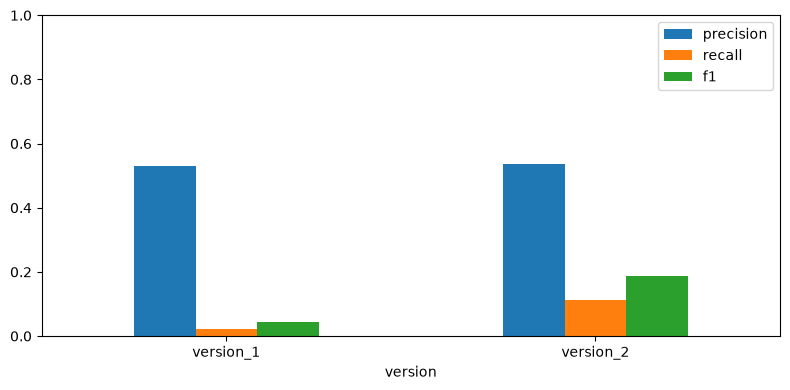

In [19]:
metrics_table[['precision', 'recall', 'f1']].plot.bar(rot=0, figsize=(8, 4), ylim=(0, 1))
plt.tight_layout()
plt.show()
